In [1]:
# Installe ces bibliothèques si ce n'est pas déjà fait sur ta machine
!pip install torch transformers captum pandas matplotlib seaborn

In [2]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
#AutoTokenizer = transform model into a numerical representation (token slicing)
#AutoModelForSequenceClassification = allows us to charge a Transformer model for classification of sequences

model_name = "distilbert-base-uncased-finetuned-sst-2-english"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name, output_attentions=True)
#from_pretrained = retrieve pre-fitted files associed to the model
#self_attention = allows us to take into account the relation between tokens, rather than just take the tokens alone
#output_attentions=True : allows us to retrieve the result of self_attention

model.eval() #evalution mode (≠ train mode)
print(f"Modèle {model_name} chargé avec succès !")

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

W1123 17:15:02.309000 23258 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Modèle distilbert-base-uncased-finetuned-sst-2-english chargé avec succès !


In [3]:
text1 = "I love machine learning."
text2 = "Otherwise it's hard to learn it."

tokens = tokenizer(text1, text2)
print(tokens)

#input_ids = numerical representation of the sentence
#token_type_ids = to see to which part of text belong each token (1 variable of text = 1 idx)
#attention_mask = indicates to the model which word should be taken into account (0 = padding token, for having the same length in sentences f.e)

{'input_ids': [101, 1045, 2293, 3698, 4083, 1012, 102, 4728, 2009, 1005, 1055, 2524, 2000, 4553, 2009, 1012, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


In [30]:
text = "The scenario is brilliant but the acting is terrible." #2 opposite sentiments
 
inputs = tokenizer([text], return_tensors="pt") #transform the sentence into numerical tokens and return the result with pytorch tensor form
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0]) #convert_ids_to_tokens : transform numerical ids to readables token

with torch.no_grad(): #disable the gradient computation, we don't train the model, we are using it
    outputs = model(**inputs) #give the data to the model (**inputs --> allow us to give the data with a dictionary form)

#print(outputs)

logits = outputs.logits #logits = gross scores of the prediction
print(logits)
predicted_class_id = logits.argmax().item() #retrieve the index of the class that have the biggest score
predicted_label = model.config.id2label[predicted_class_id] #convert this index into a readable label

attentions = outputs.attentions #retrieve the attention weights computed by the differents layers of BERT
#print(attentions)

print(f"Entry text                           : {text}")
print(f"Generated token                      : {tokens}")
print(f"Final prediction                     : {predicted_label}")
print(f"Number of attention layers extracted : {len(attentions)}")
print(f"Layer Shape                          : {attentions[0].shape}") #(batch, nb_heads, tokens_query, tokens_key)
#batch = number of sentences used by the model
#nb_head = number of head attention
#tokens_query = number of token searching information (search information)
#tokens_key = number of token of which the attention is computed (provide information)
#self_attention --> capacity of a model to allow each word of the sentence to see all other words of the sentence for a better understanding

tensor([[ 2.7148, -2.3865]])
Entry text                           : The scenario is brilliant but the acting is terrible.
Generated token                      : ['[CLS]', 'the', 'scenario', 'is', 'brilliant', 'but', 'the', 'acting', 'is', 'terrible', '.', '[SEP]']
Final prediction                     : NEGATIVE
Number of attention layers extracted : 6
Layer Shape                          : torch.Size([1, 12, 12, 12])


In [ ]:
import torch.nn.functional as F

probs = F.softmax(logits, dim=-1)[0] #softmax = convert gross score in probabilities

base_prob = probs[predicted_class_id].item() #predicted_class_id = the index of the class that have the biggest score
base_logit = logits[0, predicted_class_id].item() #gross score of the model, the logits

line_sum = attentions[-1][0, 0, 0, :].sum().item() #-1 : retrieve the last attention layer of BERT

print("Probabilities (use of softmax)       : ",probs)
print("Probabilities of the predicted class : ", base_prob)
print("Logit of the predicted class         : ", base_logit)
print("Sum of weights on 1 line             : ", int(line_sum))

Probabilities (use of softmax)       :  tensor([0.9939, 0.0061])
Probabilities of the predicted class :  0.9939477443695068
Logit of the predicted class         :  2.71475887298584
Sum of weights on 1 line             :  1


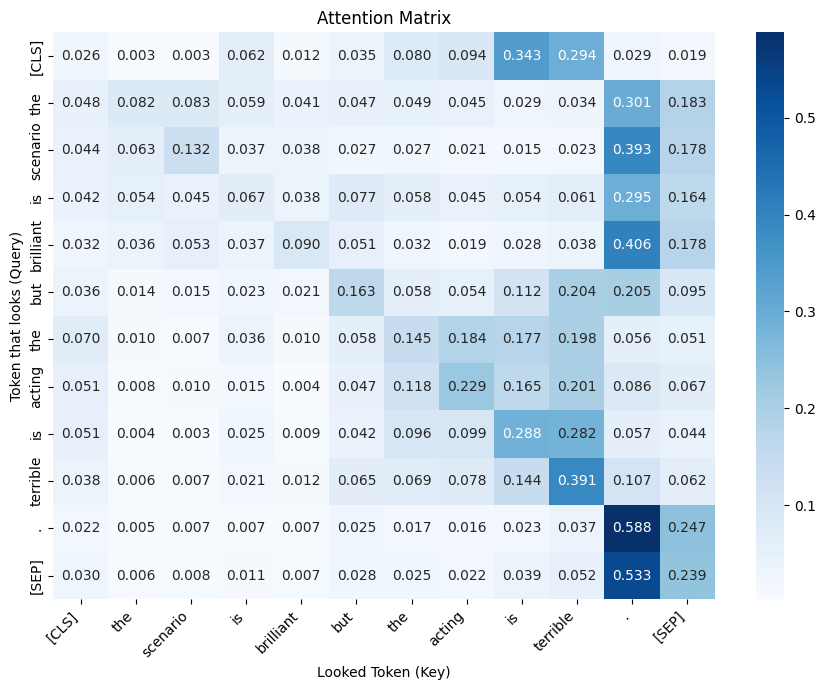

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

attn_last_layer = attentions[-1][0].mean(dim=0).numpy() #(1,12,12,12) --> (12,12)

plt.figure(figsize=(9, 7))
sns.heatmap(
    attn_last_layer,
    xticklabels=tokens,
    yticklabels=tokens,
    cmap="Blues",
    annot=True,
    fmt=".3f",
)
plt.xlabel("Looked Token (Key)")
plt.ylabel("Token that looks (Query)")
plt.title("Attention Matrix")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 📊 Analysis of Graph 1: Attention Matrix (Last Layer, Head-Averaged)

Looking at this heatmap, three major behaviors stand out:

1. **The "Attention Sink" Effect**: If you look at the rows for most normal words ("the", "scenario", "brilliant", etc.), they don't look at each other. Instead, they heavily dump their attention onto the punctuation mark (`.`) and the `[SEP]` token (e.g., "scenario" puts 0.393 on the dot). The model uses these neutral tokens as a "trash bin" for unneeded information.
2. **The `[CLS]` Decision Pattern**: The `[CLS]` token (which determines the final prediction) acts completely differently. It ignores the punctuation sink and focuses heavily on the bigram **"is" (0.343)** and **"terrible" (0.294)**. Interestingly, the auxiliary verb "is" gets a slightly higher weight than the actual negative adjective "terrible". This shows the model relies on the grammatical structure "is + adjective" to classify the sentiment.
3. **Local Word Clustering**: When words do look at each other, they tend to cluster in small local contexts (e.g., "terrible" looks at itself 0.391 and at the "is" right before it 0.144). This highlights that the last layer focuses on short semantic chunks rather than global sentence context.

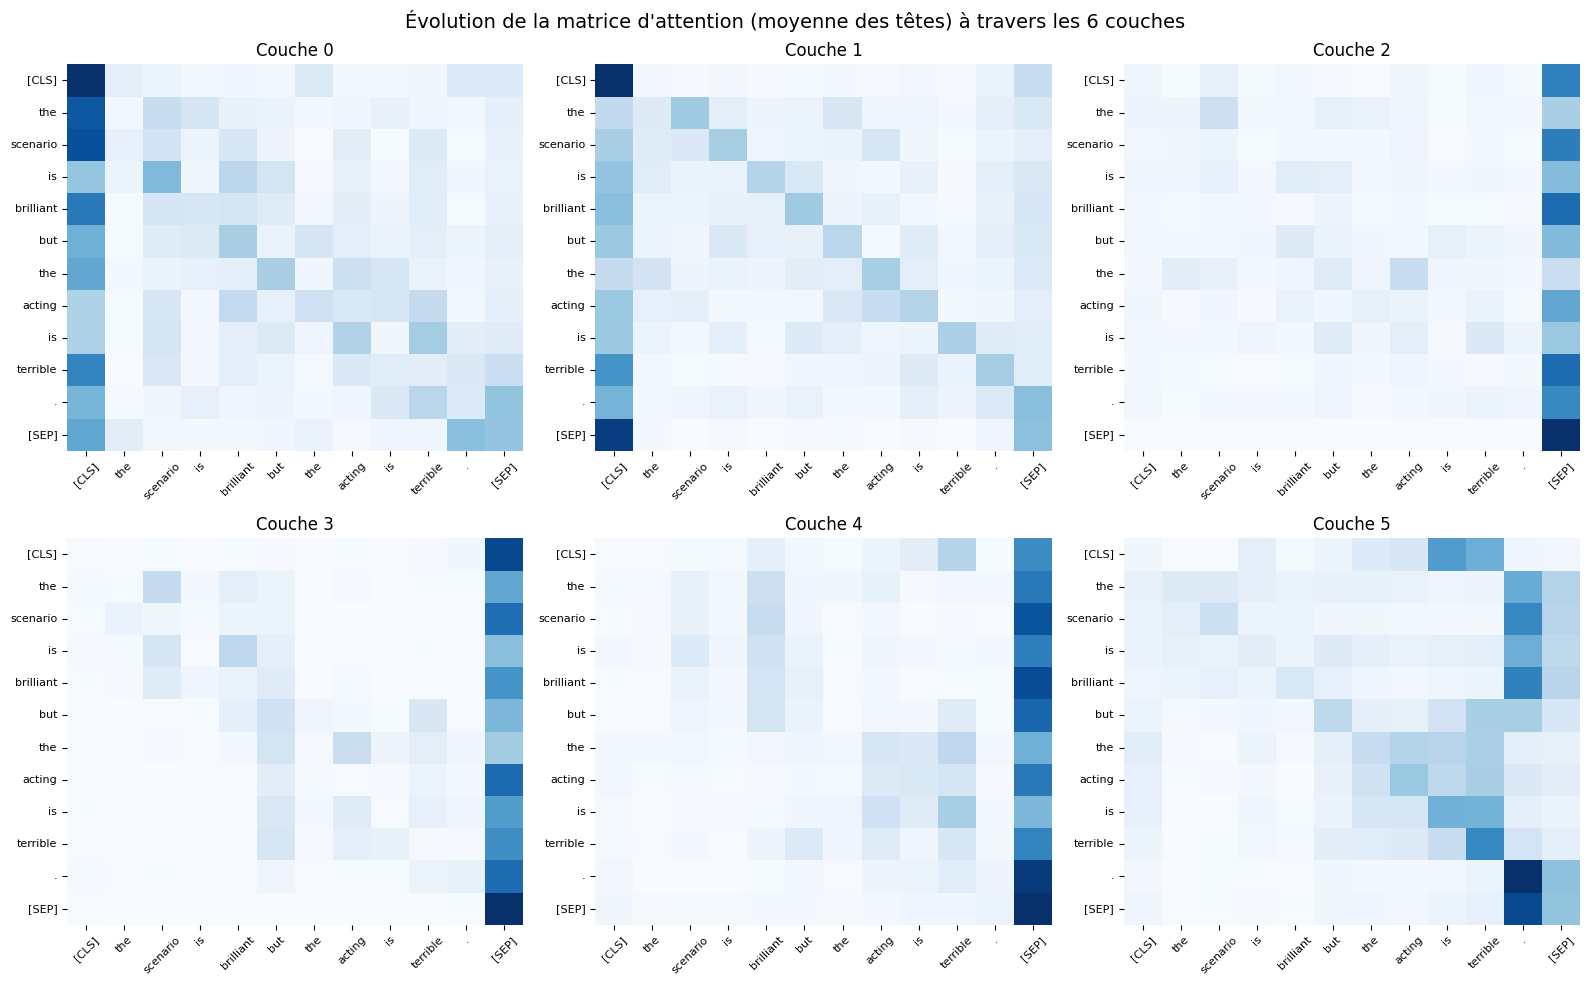

In [36]:
# Visualisation des 6 couches côte à côte (moyenne des 12 têtes par couche)
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for layer_idx, ax in enumerate(axes.flat):
    layer_mat = attentions[layer_idx][0].mean(dim=0).numpy()
    sns.heatmap(
        layer_mat,
        xticklabels=tokens,
        yticklabels=tokens,
        cmap="Blues",
        cbar=False,
        ax=ax
    )
    ax.set_title(f"Couche {layer_idx}")
    ax.tick_params(axis='x', rotation=45, labelsize=8)
    ax.tick_params(axis='y', labelsize=8)

plt.suptitle("Évolution de la matrice d'attention (moyenne des têtes) à travers les 6 couches", fontsize=14)
plt.tight_layout()
plt.show()

### 📈 Analysis of Graph 2: Layer-by-Layer Attention Evolution

This grid perfectly illustrates how a Transformer builds understanding hierarchically, layer by layer:

*   **Layer 0 (Raw Input)**: Attention is very diffuse and broad. The `[CLS]` token strongly looks at the first words ("the", "scenario"), but the model doesn't understand the meaning yet; it is just indexing positions.
*   **Layer 1 (Local Syntax)**: A clear diagonal starts to appear. Words begin to look at themselves and their immediate neighbors. The model is building local grammatical structures.
*   **Layers 2, 3 & 4 (The `[SEP]` Black Hole)**: This is striking. Almost all tokens dump their attention massively onto the `[SEP]` token (the dark blue column on the right). The model pauses information processing and compresses the sentence context into a neutral state.
*   **Layer 5 (Semantic Extraction)**: The final layer "wakes up." The `[SEP]` sink is abandoned. The punctuation mark (`.`) becomes the new sink for filler words, while the `[CLS]` token finally isolates the crucial semantic evidence: the "is terrible" chunk, enabling the final classification decision.